# Notebook 03: Bootstrap Aggregation ($63.2\%$ Law), Out-of-Bag Error & Random Forests

In this notebook we explore:
1. **Empirical Verification of the $1 - (1 - \frac{1}{m})^m \to 1 - e^{-1} \approx 63.21\%$ Bootstrap Law:** Measuring the exact fraction of unique in-bag samples and $36.79\%$ Out-of-Bag (OOB) samples across sample sizes $m$.
2. **Variance Reduction on Noisy Decision Boundaries:** Contrasting a single deep Decision Tree ($B = 1$, jagged high-variance rectangles memorizing noise) against a 60-tree Random Forest ($B = 60$, smooth generalized manifold).
3. **OOB Error vs. Independent Test Error Convergence:** Tracking ensemble error as the number of trees $B$ grows from $1$ to $60$.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.plot_theme import (
    AMBER,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    apply_github_dark_style,
    plot_decision_boundary,
    save_fig,
)
from src.trees_engine import DecisionTreeClassifierScratch, RandomForestScratch

apply_github_dark_style()

## 1. Verifying the $1 - e^{-1} \approx 63.212\%$ Bootstrap Sampling Law

In [2]:
rng = np.random.default_rng(42)
m_values = [10, 25, 50, 100, 250, 1000, 5000]
theoretical_asymp = 1.0 - np.exp(-1.0)

print(f"{'Sample Size m':<15} | {'Exact 1 - (1 - 1/m)^m':<24} | {'Empirical Monte Carlo (200 draws)':<32}")
print("-" * 76)
for m_v in m_values:
    exact_prob = 1.0 - ((1.0 - 1.0 / m_v) ** m_v)
    emp_fracs = [np.unique(rng.integers(0, m_v, size=m_v)).size / float(m_v) for _ in range(200)]
    print(f"{m_v:<15d} | {exact_prob*100:21.3f}%  | {np.mean(emp_fracs)*100:29.3f}%")

Sample Size m   | Exact 1 - (1 - 1/m)^m    | Empirical Monte Carlo (200 draws)
----------------------------------------------------------------------------
10              |                65.132%  |                        64.250%
25              |                63.960%  |                        63.560%
50              |                63.583%  |                        63.110%
100             |                63.397%  |                        63.625%
250             |                63.286%  |                        63.248%
1000            |                63.230%  |                        63.167%
5000            |                63.216%  |                        63.185%


## 2. Comparing Single Decision Tree ($B=1$) vs. Random Forest ($B=60$) on Noisy Moons


Single Deep Tree (B=1)  | Train Acc: 100.0% | Test Acc: 90.0%
Random Forest (B=60)    | Train Acc: 100.0% | Test Acc: 91.7% | OOB Acc: 92.5%


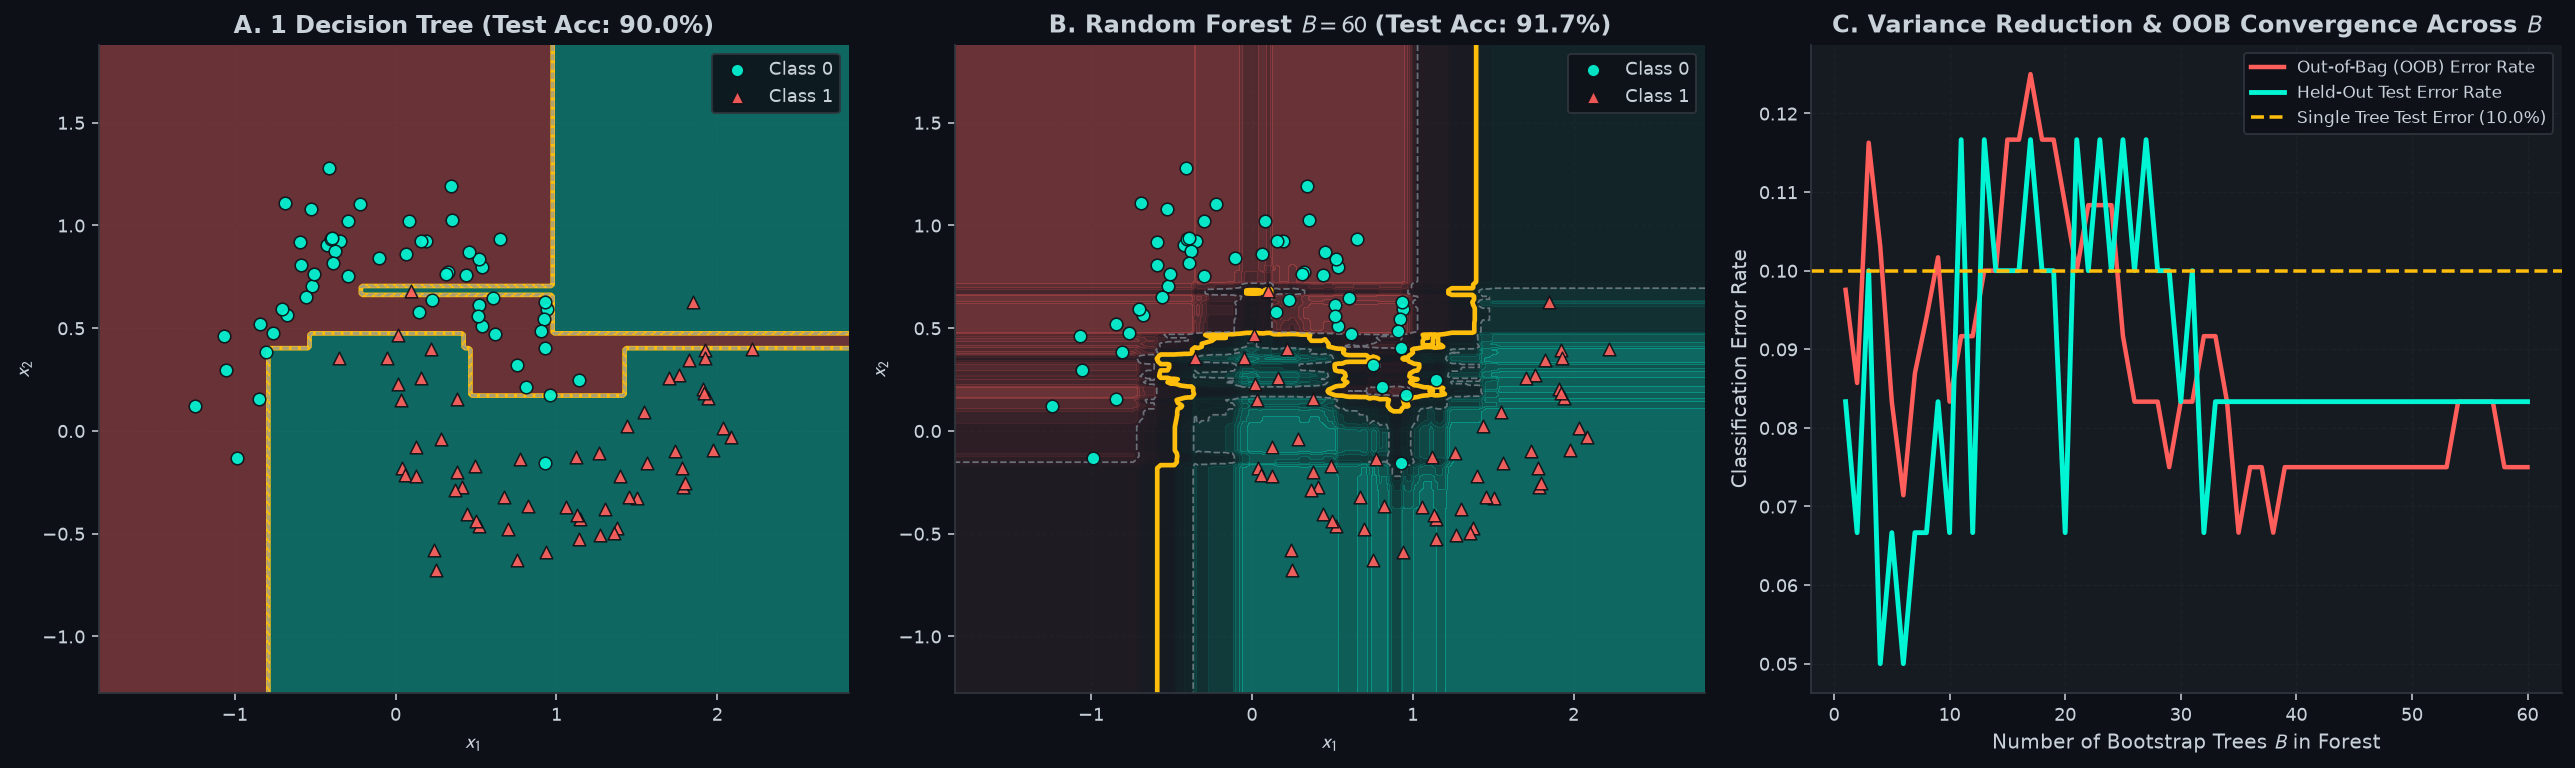

In [3]:
m_pts = 180
theta = np.linspace(0, np.pi, m_pts // 2)
# Crescent 1
x1_top = np.cos(theta) + rng.normal(0, 0.16, size=m_pts // 2)
x2_top = np.sin(theta) + rng.normal(0, 0.16, size=m_pts // 2)
# Crescent 2
x1_bot = 1.0 - np.cos(theta) + rng.normal(0, 0.16, size=m_pts // 2)
x2_bot = 1.0 - np.sin(theta) - 0.5 + rng.normal(0, 0.16, size=m_pts // 2)

X_moons = np.vstack([np.column_stack([x1_top, x2_top]), np.column_stack([x1_bot, x2_bot])])
y_moons = np.concatenate([np.zeros(m_pts // 2, dtype=int), np.ones(m_pts // 2, dtype=int)])

# Split train/test
perm = rng.permutation(m_pts)
n_train = 120
train_idx, test_idx = perm[:n_train], perm[n_train:]
X_train_m, y_train_m = X_moons[train_idx], y_moons[train_idx]
X_test_m, y_test_m = X_moons[test_idx], y_moons[test_idx]

single_tree = DecisionTreeClassifierScratch(max_depth=12, min_samples_split=2).fit(X_train_m, y_train_m)
single_test_acc = float(np.mean(single_tree.predict(X_test_m) == y_test_m))

B_total = 60
rf_forest = RandomForestScratch(
    n_estimators=B_total,
    max_depth=10,
    max_features="sqrt",
    random_state=42,
).fit(X_train_m, y_train_m)
rf_test_acc = float(np.mean(rf_forest.predict(X_test_m) == y_test_m))

print(f"\nSingle Deep Tree (B=1)  | Train Acc: {np.mean(single_tree.predict(X_train_m) == y_train_m)*100:.1f}% | Test Acc: {single_test_acc*100:.1f}%")
print(f"Random Forest (B={B_total})    | Train Acc: {np.mean(rf_forest.predict(X_train_m) == y_train_m)*100:.1f}% | Test Acc: {rf_test_acc*100:.1f}% | OOB Acc: {rf_forest.oob_score_*100:.1f}%")

# Compute cumulative OOB and test error curves across B
oob_votes_running = np.zeros((n_train, 2), dtype=np.float64)
oob_counts_running = np.zeros(n_train, dtype=np.int64)
test_probs_running = np.zeros((X_test_m.shape[0], 2), dtype=np.float64)

oob_err_curve = []
test_err_curve = []
b_range = np.arange(1, B_total + 1)

for b_idx in range(B_total):
    tree_b = rf_forest.trees_[b_idx]
    oob_idx_b = rf_forest.oob_indices_[b_idx]
    if oob_idx_b.size > 0:
        oob_votes_running[oob_idx_b] += tree_b.predict_proba(X_train_m[oob_idx_b])
        oob_counts_running[oob_idx_b] += 1

    valid = oob_counts_running > 0
    oob_pred_b = np.argmax(oob_votes_running[valid], axis=1)
    oob_err_curve.append(1.0 - float(np.mean(oob_pred_b == y_train_m[valid])))

    test_probs_running += tree_b.predict_proba(X_test_m)
    test_pred_b = np.argmax(test_probs_running, axis=1)
    test_err_curve.append(1.0 - float(np.mean(test_pred_b == y_test_m)))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18.5, 5.6))

# Panel A: Single Deep Tree Boundary
plot_decision_boundary(
    predict_fn=lambda grid: single_tree.predict_proba(grid)[:, 1],
    X=X_train_m,
    y=y_train_m,
    ax=ax1,
    title=f"A. 1 Decision Tree (Test Acc: {single_test_acc*100:.1f}%)",
)

# Panel B: Random Forest Ensemble Boundary
plot_decision_boundary(
    predict_fn=lambda grid: rf_forest.predict_proba(grid)[:, 1],
    X=X_train_m,
    y=y_train_m,
    ax=ax2,
    title=f"B. Random Forest $B=60$ (Test Acc: {rf_test_acc*100:.1f}%)",
)

# Panel C: OOB Error & Test Error Convergence vs Number of Trees B
ax3.plot(b_range, oob_err_curve, color=CORAL, linewidth=2.3, label="Out-of-Bag (OOB) Error Rate")
ax3.plot(b_range, test_err_curve, color=CYAN, linewidth=2.5, label="Held-Out Test Error Rate")
ax3.axhline(1.0 - single_test_acc, color=AMBER, linestyle="--", linewidth=1.8, label=f"Single Tree Test Error ({(1-single_test_acc)*100:.1f}%)")
ax3.set_xlabel("Number of Bootstrap Trees $B$ in Forest")
ax3.set_ylabel("Classification Error Rate")
ax3.set_title("C. Variance Reduction & OOB Convergence Across $B$")
ax3.legend(loc="upper right", fontsize=8.5)

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "04_rf_variance_reduction_boundary.png")
plt.show()